In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import Spectral_Preprocessing as sp

from argparse import ArgumentParser, Namespace
from scipy import stats

In [2]:
parser = ArgumentParser()
parser.add_argument("--range-min-ir", dest= "range_min_ir", type = int, default = 400)
parser.add_argument("--range-max-ir", dest= "range_max_ir", type = int, default = 4000)
parser.add_argument("--interpolate-interval-ir", dest = "interpolate_interval_ir", type = int, default = 1) 

parser.add_argument("--range-min-raman", dest= "range_min_raman", type = float, default = 400)
parser.add_argument("--range-max-raman", dest= "range_max_raman", type = float, default = 4000)
parser.add_argument("--interpolate-interval-raman", dest = "interpolate_interval_raman", type = float, default = 1) 

parser.add_argument("--rubberband", dest="rubberband", action="store_true", default=False,)
parser.add_argument("--minmax", dest="minmax", action="store_true", default=False,)
parser.add_argument("--no-interpolate", dest = "no_interpolate", action="store_true", default = False)
parser.add_argument("--nitrogen-calibration", dest="nitrogen_calibration", action="store_true", default=True,)
parser.add_argument("--si-peak", dest= "si_peak", type = float, default = 520)

parser.add_argument("--smooth", dest = "smooth", type = int, default = 0)
parser.add_argument("--baseline", dest = "baseline", type = int, default = 5)


_StoreAction(option_strings=['--baseline'], dest='baseline', nargs=None, const=None, default=5, type=<class 'int'>, choices=None, required=False, help=None, metavar=None)

In [3]:
###Sample Code #1: Specify IR and Raman interpolation intervals along with min & max values
args: Namespace = parser.parse_args([]) ###Do not alter this section.
###PLEASE TYPE IN YOUR ARGUMENTS HERE
args.wn_range_ir_1 = (980, 1800)
args.wn_range_ir_2 = (2720, 2980)
args.range_min_ir = 675.0 #674.9918 ###enter an integer
args.range_max_ir = 4000.0 #3999.809 ###enter an integer [max value is not included]
args.interpolate_interval_ir = 2 #1.929 ###enter an integer
args.finger_print_exl = False
args.background_rule = 'total_var'
args.ths_mean_int_ir = 0.043
args.ths_tot_var_int_ir = 0.59

args.range_min_raman = 355 #.555542 ###enter an integer or float 
args.range_max_raman = 3500 #3895.935059 ##enter an integer or float [max value is not included] 
args.interpolate_interval_raman = 2.0 #168021680216802 ###enter an integer or float

args.rubberband = 'specy' ###True for rubberband, False for iModPoly
args.minmax = 'snv' ###False for SVT normalization, True for minmax
args.no_interpolate = False ###use sample code 2 if using True for this option.
args.nitrogen_calibration = True ##True for calibration, False for no calibration.
args.si_peak = 520 ###enter an integer or float



In [4]:
#directory_name = '/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/MEC_02_115/Raw Data/' ###directory where the PTIR files will be downloaded from.
directory_name = 'MEC_02_115/Raw Data/' ###directory where the PTIR files will be downloaded from.
ir_export_filename =  "no_interpolate_equiv_ir.csv"  ###enter your desired export Raman csv filename, in quotes
raman_export_filename =  "no_interpolate_equiv_raman.csv"  ###enter your desired export Raman csv filename, in quotes
file_list_tmp = [] ###option to list out the files you want included. if left as-is, all files in directory will be included.

path = 'Reference_library_reb/'
dirs = os.listdir(path)
dirs = [x for x in dirs if x not in ['.DS_Store', 'Archive for reference data', 'Processed']]

file_list = []
for d in dirs:
    #print(os.listdir(path + d + '/Data/Processed/mIRage OPTIR+Raman/'))
    path_2 = path + d + '/Data/Processed/mIRage OPTIR+Raman/'
    dirs_2 = os.listdir(path_2)
    #file_list = file_list + [path_2 + dd for dd in dirs_2 if dd[-4:] == "xlsx"]
    file_list = file_list + [path_2 + dd for dd in dirs_2 if (dd[-9:] == "data.xlsx" or dd[-12:] == "spectra.xlsx")]
file_list = file_list + [d + '/' + dd for dd in dirs_2 if (dd[-9:] == "data.xlsx" or dd[-12:] == "spectra.xlsx")]

polymer_list = np.array(['sucrose', 'PE', 'PSL', 'NaNO3', 'NH2SO4', 'PP'])

wn_list = []
df_list = []
for i, f in enumerate(file_list):
    df = pd.read_excel(f, sheet_name=None)#['Raman', 'Raman spectra']
    print(f)
    if 'Raman' in df.keys():
        df_raman = df['Raman']
    elif 'Raman spectra' in df.keys():
        df_raman = df['Raman spectra']
    df_raman.columns = ['wavenumber'] + list(range(df_raman.shape[1]-1))#.set_index('X value [cmâ»Â¹]')
    df_raman = df_raman.set_index('wavenumber')
    df_raman = df_raman.T.reset_index(drop=True)
    df_raman['polymer'] = polymer_list[[p in f for p in polymer_list]][0]#polymer[i]
    df_raman['map_x'] = 0
    df_raman['map_y'] = 0
    
    if 'O-PTIR' in df.keys():
        df_ir = df['O-PTIR']
    elif 'PTIR spectra' in df.keys():
        df_ir = df['PTIR spectra']
    df_ir.columns = ['wavenumber'] + list(range(df_ir.shape[1]-1))#.set_index('X value [cmâ»Â¹]')
    df_ir = df_ir.set_index('wavenumber')
    df_ir = df_ir.T.reset_index(drop=True)
    df_ir['polymer'] = polymer_list[[p in f for p in polymer_list]][0]#polymer[i]
    df_ir['map_x'] = 0
    df_ir['map_y'] = 0
    
    df_list.append([df_ir,df_raman])
#df_all_raman = pd.concat(df_list, axis=0).reset_index(drop=True)

Reference_library_reb/20230708 0.05 M sucrose/Data/Processed/mIRage OPTIR+Raman/20240509_50mMsucrose_RP_mIRage_allccdata.xlsx
Reference_library_reb/20230423 1.0 and 3.0 um PSL/Data/Processed/mIRage OPTIR+Raman/20230424_1and3umPSL_allccdata.xlsx
Reference_library_reb/20230708 0.05 M NaNO3/Data/Processed/mIRage OPTIR+Raman/20240509_50mMNaNO3_RP_mIRage_allccdata.xlsx
Reference_library_reb/20230707 200 to 9900 nm PE EtOH iced atomized/Data/Processed/mIRage OPTIR+Raman/20230707_200to9900nmPE_EtOHiced_atomized_mIRage_allccdata.xlsx
Reference_library_reb/20230708 0.05 M NH2SO4/Data/Processed/mIRage OPTIR+Raman/20240509_50mMNH42SO4_RP_mIRage_allccdata.xlsx
Reference_library_reb/20230906 1 to 5 um PP 50-50 EtOH-Omni 2 min sonication iced/Data/Processed/mIRage OPTIR+Raman/20230906_1to5umPP_2minsonic_iced_30minMPSstg2_allspectra.xlsx


In [5]:
raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, _, rng, ir_bg_label, saturated_wn_list = sp.df_to_interpolated_processed_csv(args, directory_name=None, ir_export_filename=None, raman_export_filename=None, file_list = df_list, transpose = True)


In [6]:
pol_table = pd.DataFrame({'file':[polymer_list[[p in f for p in polymer_list]][0] for f in file_list]})
pol_table

,file
0,sucrose
1,PSL
2,NaNO3
3,PE
4,NH2SO4
5,PP


In [7]:
saturated_wn_list

[array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),
 array([], dtype=int64),


In [19]:
preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['id'] = pol_table.iloc[ids,:].reset_index(drop=True)
preposs_data_raman.to_csv('gloves_contamination/data_raman_rebecca_specy.csv')
preposs_data_raman

preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['id'] = pol_table.iloc[ids,:].reset_index(drop=True)
preposs_data_ir.to_csv('gloves_contamination/data_ir_rebecca_no_base_line_correction.csv')
preposs_data_ir


,355.5555419921875,357.72357177734375,359.8915710449219,362.0596008300781,364.2276306152344,366.3956604003906,368.56365966796875,370.731689453125,372.89971923828125,375.0677490234375,...,3882.9267578125,3885.0947265625,3887.262939453125,3889.430908203125,3891.598876953125,3893.766845703125,3895.93505859375,map_x,map_y,id
0,0.670429,0.692583,0.691150,0.690130,0.689431,0.684363,0.675577,0.660505,0.655774,0.656307,...,-1.985907,-1.985907,-1.985907,-1.985907,-1.985907,-1.985907,-1.985907,0,0,sucrose
1,0.674347,0.677416,0.687415,0.691313,0.690482,0.668473,0.665706,0.698516,0.726738,0.746556,...,-1.998551,-1.998551,-1.998551,-1.998551,-1.998551,-1.998551,-1.998551,0,0,sucrose
2,0.543696,0.594869,0.587169,0.597654,0.622237,0.621948,0.617946,0.609104,0.612459,0.619774,...,-2.054987,-2.054987,-2.054987,-2.054987,-2.054987,-2.054987,-2.054987,0,0,sucrose
3,0.674831,0.690824,0.692268,0.695971,0.701424,0.704318,0.703799,0.697411,0.698074,0.697468,...,-1.962383,-1.962383,-1.962383,-1.962383,-1.962383,-1.962383,-1.962383,0,0,sucrose
4,0.686135,0.717307,0.732168,0.729018,0.711905,0.675756,0.667211,0.708909,0.734139,0.751460,...,-1.909806,-1.909806,-1.909806,-1.909806,-1.909806,-1.909806,-1.909806,0,0,sucrose
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
520,-2.389919,-2.438852,-2.393252,-2.364148,-2.347832,-2.345281,-2.338746,-2.324189,-2.336535,-2.346374,...,0.173606,0.173606,0.173606,0.173606,0.173606,0.173606,0.173606,0,0,PP
521,-0.475473,-0.459012,-0.445544,-0.445020,-0.454529,-0.462873,-0.463170,-0.449289,-0.446548,-0.445196,...,-0.610937,-0.610937,-0.610937,-0.610937,-0.610937,-0.610937,-0.610937,0,0,PP
522,-0.473115,-0.468539,-0.469620,-0.471380,-0.473667,-0.474055,-0.475275,-0.478101,-0.456185,-0.426254,...,-0.592929,-0.592929,-0.592929,-0.592929,-0.592929,-0.592929,-0.592929,0,0,PP
523,-0.458496,-0.483453,-0.485274,-0.478952,-0.466316,-0.462382,-0.458232,-0.453093,-0.426640,-0.391141,...,-0.555166,-0.555166,-0.555166,-0.555166,-0.555166,-0.555166,-0.555166,0,0,PP


,981.7028198242188,983.6317749023438,985.560791015625,987.4898071289062,989.4188232421875,991.3477783203125,993.2767944335938,995.205810546875,997.1348266601562,999.0637817382812,...,2937.708740234375,2939.6376953125,2941.56689453125,2943.495849609375,2945.4248046875,2947.353759765625,2949.28271484375,map_x,map_y,id
0,-0.401827,-0.463463,-0.473798,-0.339089,-0.098811,0.164316,0.154343,0.151346,0.192657,0.137080,...,-0.101273,-0.183481,-0.142811,-0.440282,-0.471932,-0.614550,-0.395966,0,0,sucrose
1,-0.735355,-0.400440,-0.287544,-0.171657,-0.164141,-0.168486,-0.000286,0.146953,0.157312,0.137237,...,0.675356,0.429463,0.371468,0.473038,0.322285,0.077029,-0.079454,0,0,sucrose
2,-0.498098,-0.422704,-0.327168,-0.234739,-0.069773,-0.048106,-0.050230,0.049625,0.106016,0.024574,...,0.467386,0.519921,0.511605,0.236771,0.262502,0.246592,0.315130,0,0,sucrose
3,0.244668,-0.212702,-0.974683,-0.748355,-0.636713,-0.696571,-0.788060,-1.001306,-0.777278,-0.135817,...,0.000685,1.557510,2.411203,-0.098691,-2.336531,1.038341,1.689249,0,0,sucrose
4,-0.705346,0.469284,-0.464227,0.475477,0.593782,0.065262,-0.112839,-0.226445,-0.041276,0.141429,...,-5.673658,-2.940406,-2.331532,-1.864238,-1.713725,-4.577235,-6.034589,0,0,sucrose
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
520,-1.353644,-0.987321,0.562518,1.909195,2.642873,1.454772,-0.025428,-0.552775,0.452344,0.878707,...,-2.261386,-1.163968,1.621965,1.084568,-1.733686,-3.045288,1.977605,0,0,PP
521,-0.646934,-0.559116,-0.565326,-0.575787,-0.539427,-0.516935,-0.444229,-0.363769,-0.328688,-0.300677,...,1.268016,1.251562,1.834194,2.267505,2.589100,2.871976,2.791154,0,0,PP
522,-0.397214,-0.493543,-0.486861,-0.479381,-0.472249,-0.503640,-0.458743,-0.333185,-0.348451,-0.400086,...,1.658360,1.887118,2.124598,2.519634,3.254894,3.933142,4.260059,0,0,PP
523,-0.968060,-1.079775,-0.823164,-0.690574,-0.530152,-0.592429,-0.449904,-0.419264,-0.368320,-0.195293,...,0.725628,-0.214792,-0.656875,0.914279,1.981162,1.220596,1.430657,0,0,PP


In [14]:
raman_final.shape, ir_final.shape

((525, 1634), (525, 544))

In [15]:
wn = np.array(XX_ir)

idx = np.logical_or(np.logical_and(wn > 980, wn < 1800),
np.logical_and(wn > 2720, wn < 2950) #2993.64990234375-10
) 
#2720, 2950

In [16]:
np.unique(label_list)

array(['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'], dtype='<U7')

NH2SO4


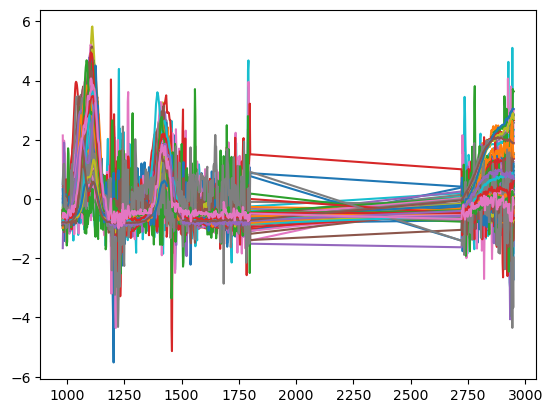

NaNO3


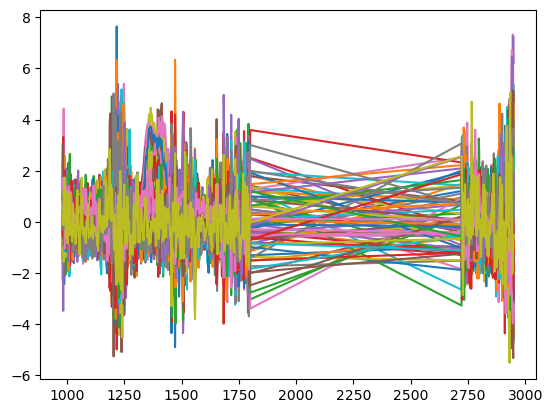

PE


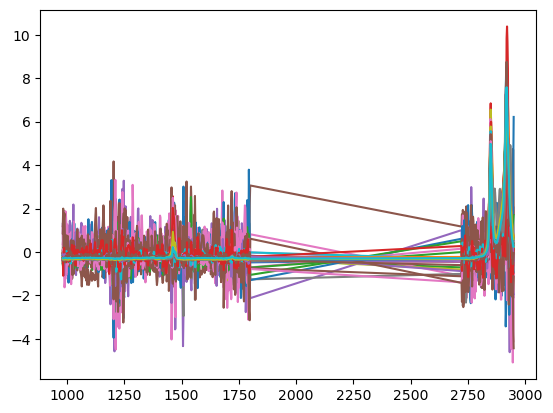

PP


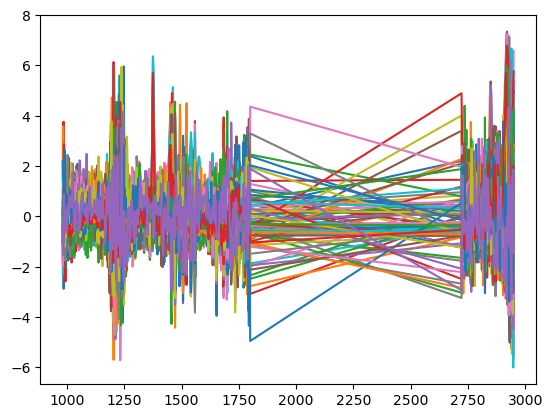

PSL


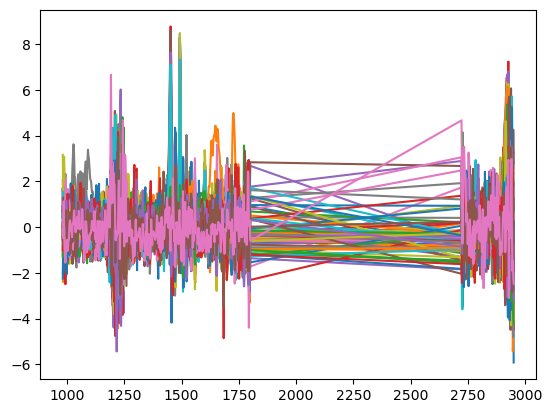

sucrose


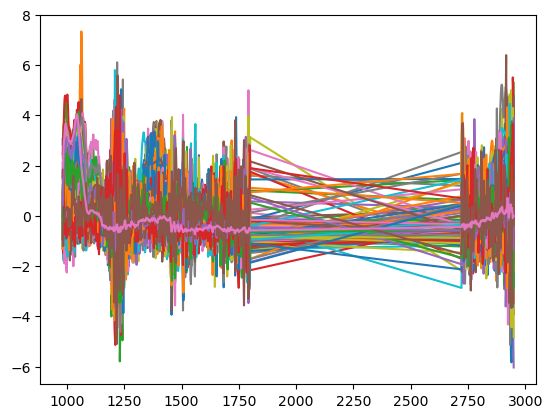

In [17]:
for label in np.unique(label_list):
    print(label)
    _ = plt.plot(XX_ir[idx],
             ir_final[np.array(label_list) == label,:][:,idx].T)#, c='b', alpha=.1)
    _ = plt.show()

NH2SO4


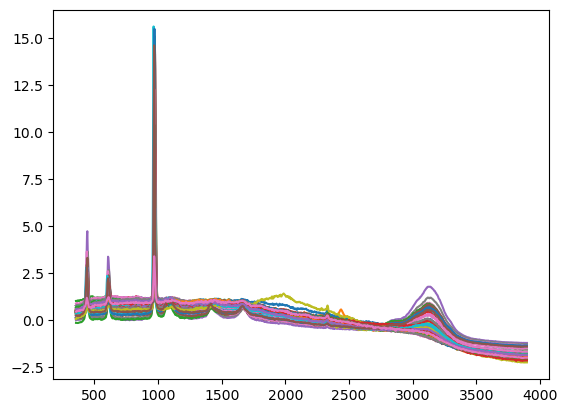

NaNO3


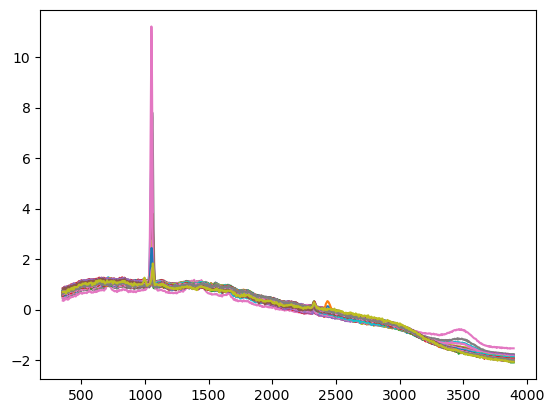

PE


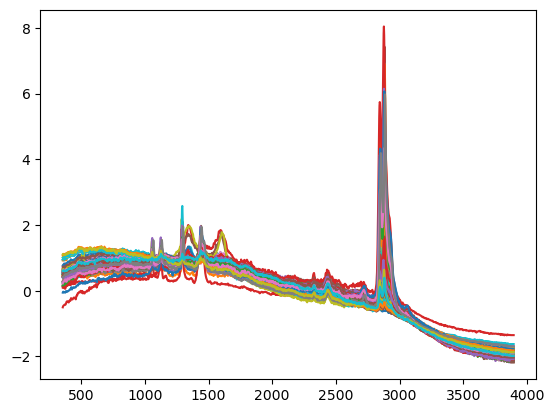

PP


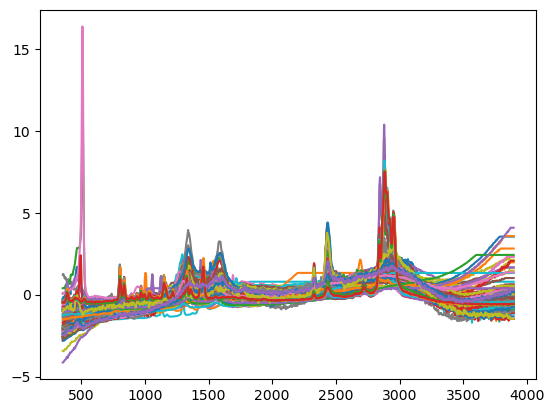

PSL


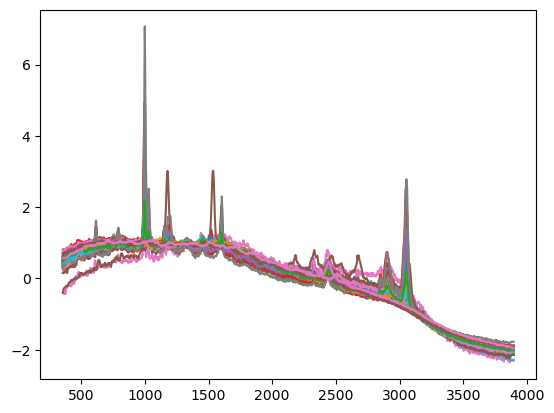

sucrose


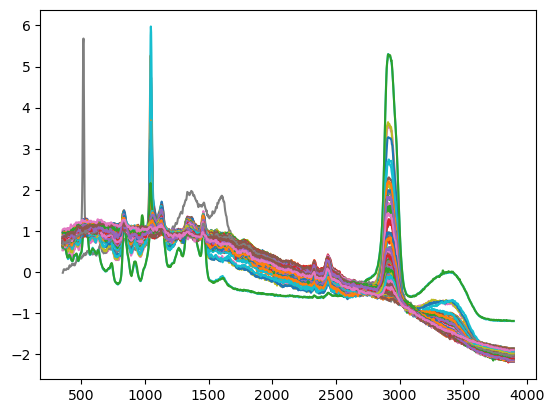

In [18]:
for label in np.unique(label_list):
    print(label)
    _ = plt.plot(XX_raman,
             raman_final[np.array(label_list) == label,:].T)
    _ = plt.show()

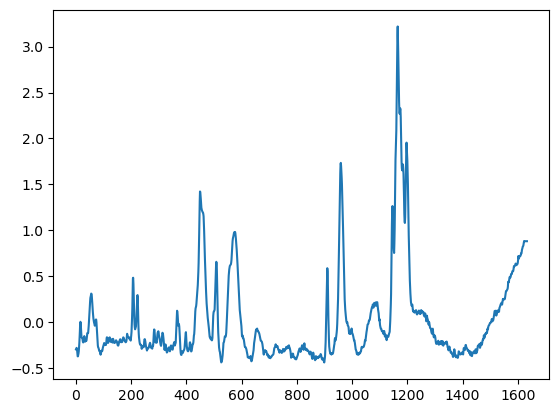

In [40]:
plt.plot(raman_final[np.array(label_list) == 'PP',:].mean(0))